# Load data

In [ ]:
import pandas as pd  

df = pd.read_csv("Salary_Data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [ ]:
df.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [ ]:
df.nunique()

Age                     41
Gender                   3
Education Level          7
Job Title              193
Years of Experience     37
Salary                 444
dtype: int64

In [ ]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

In [ ]:
df.dropna(inplace=True)

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])
df["Education Level"] = le.fit_transform(df["Education Level"])
df.head()




,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,1,0,Software Engineer,5.0,90000.0
1,28.0,0,3,Data Analyst,3.0,65000.0
2,45.0,1,5,Senior Manager,15.0,150000.0
3,36.0,0,0,Sales Associate,7.0,60000.0
4,52.0,1,3,Director,20.0,200000.0


In [ ]:
col = "Job Title"
threshold = 5  # bu sayıdan az geçen sınıflar "rare"

counts = df[col].value_counts()
rare = counts[counts < threshold]

# sınıf adları object olarak
rare_classes = rare.index.astype(object)
print(rare_classes)
print(type(rare_classes[0]))  # <class 'str'>

# sınıf adı + kaç kez geçtiği
rare_df = rare.rename_axis(col).reset_index(name="count")
rare_df


Index(['Senior Operations Coordinator', 'Senior Business Development Manager',
       'Senior Data Engineer', 'Junior Product Manager',
       'Senior Marketing Specialist', 'Senior Marketing Coordinator',
       'Juniour HR Generalist', 'Senior Financial Advisor',
       'Junior Operations Manager', 'Junior Accountant',
       ...
       'Senior Account Executive', 'Director of Business Development',
       'Junior Financial Advisor', 'Junior Operations Coordinator',
       'Senior HR Specialist', 'Junior Research Scientist',
       'Senior Product Development Manager', 'Junior Social Media Specialist',
       'Senior Software Architect', 'Social Media Man'],
      dtype='object', name='Job Title', length=117)
<class 'str'>


,Job Title,count
0,Senior Operations Coordinator,4
1,Senior Business Development Manager,4
2,Senior Data Engineer,4
3,Junior Product Manager,4
4,Senior Marketing Specialist,4
...,...,...
112,Junior Research Scientist,1
113,Senior Product Development Manager,1
114,Junior Social Media Specialist,1
115,Senior Software Architect,1


In [ ]:
rare_df.describe()

,count
count,117.000000
mean,1.495726
std,0.847145
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,4.000000


In [ ]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,1,0,Software Engineer,5.0,90000.0
1,28.0,0,3,Data Analyst,3.0,65000.0
2,45.0,1,5,Senior Manager,15.0,150000.0
3,36.0,0,0,Sales Associate,7.0,60000.0
4,52.0,1,3,Director,20.0,200000.0


In [ ]:
df["Job Title"] = le.fit_transform(df["Job Title"])
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,1,0,175,5.0,90000.0
1,28.0,0,3,18,3.0,65000.0
2,45.0,1,5,144,15.0,150000.0
3,36.0,0,0,115,7.0,60000.0
4,52.0,1,3,25,20.0,200000.0


In [ ]:
df.corr()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
Age,1.000000,0.120672,0.534761,0.166815,0.937725,0.728061
Gender,0.120672,1.000000,-0.041675,0.075484,0.105656,0.127276
Education Level,0.534761,-0.041675,1.000000,0.031186,0.532957,0.472839
Job Title,0.166815,0.075484,0.031186,1.000000,0.131194,0.064668
Years of Experience,0.937725,0.105656,0.532957,0.131194,1.000000,0.808968
Salary,0.728061,0.127276,0.472839,0.064668,0.808968,1.000000


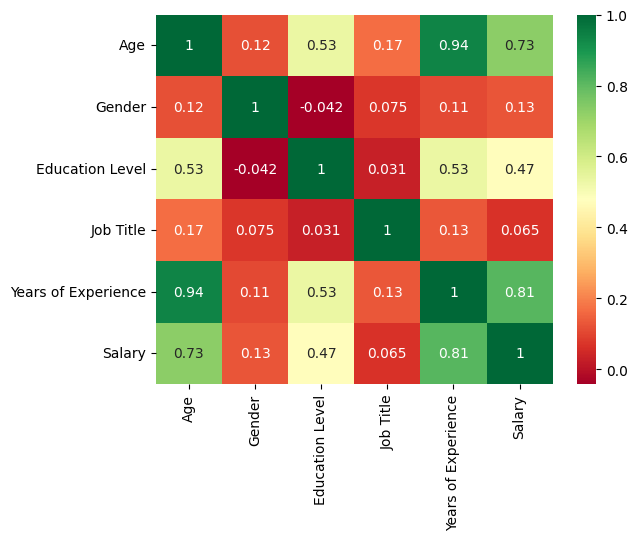

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(df.corr(), annot=True, cmap="RdYlGn")
plt.show()





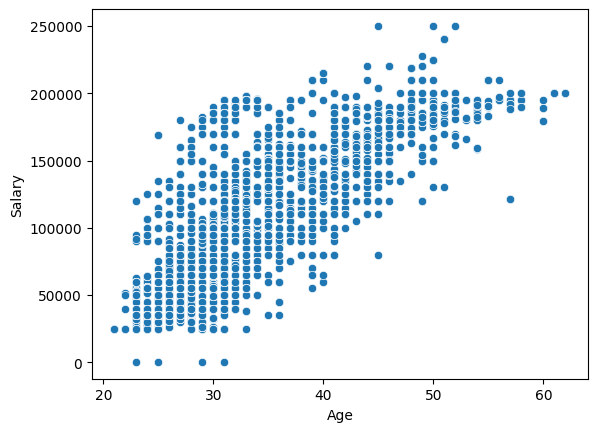

In [ ]:
# scatter plot
sns.scatterplot(x="Age", y="Salary", data=df)
plt.show()

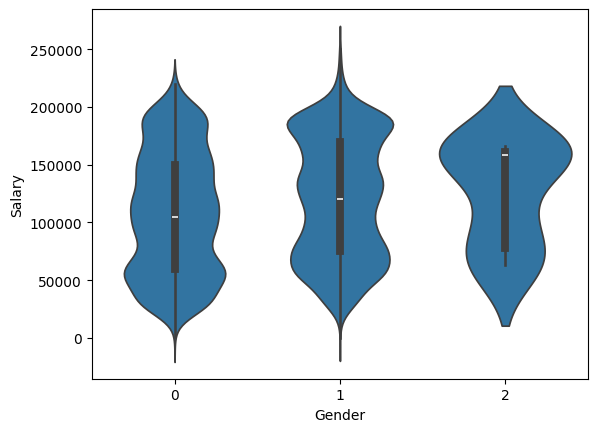

In [ ]:
# violin plot gender salary
sns.violinplot(x="Gender", y="Salary", data=df)
plt.show()

In [ ]:
# outlier detection with iqr threshold
q1 = df["Salary"].quantile(0.25)
q3 = df["Salary"].quantile(0.75)
iqr = q3 - q1
threshold = 1.5 * iqr
lower_bound = q1 - threshold
upper_bound = q3 + threshold



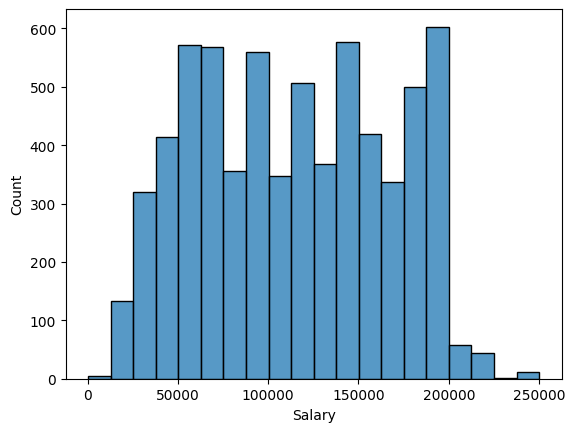

In [ ]:
#remove outliers
df = df[df["Salary"] > lower_bound]
df = df[df["Salary"] < upper_bound]

# histogram
sns.histplot(df["Salary"], bins=20)
plt.show()


In [ ]:
df.head()



,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,1,0,175,5.0,90000.0
1,28.0,0,3,18,3.0,65000.0
2,45.0,1,5,144,15.0,150000.0
3,36.0,0,0,115,7.0,60000.0
4,52.0,1,3,25,20.0,200000.0


In [ ]:
df.drop(columns=["Age"], inplace=True)

In [ ]:
df.head()


,Gender,Education Level,Job Title,Years of Experience,Salary
0,1,0,175,5.0,90000.0
1,0,3,18,3.0,65000.0
2,1,5,144,15.0,150000.0
3,0,0,115,7.0,60000.0
4,1,3,25,20.0,200000.0


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Salary"])
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
X

,Gender,Education Level,Job Title,Years of Experience
0,1,0,175,5.0
1,0,3,18,3.0
2,1,5,144,15.0
3,0,0,115,7.0
4,1,3,25,20.0
...,...,...,...,...
6699,0,5,33,20.0
6700,1,2,115,3.0
6701,0,1,41,4.0
6702,1,4,96,14.0


In [ ]:
X_train

array([[ 0.89507087,  0.79000963,  0.68633278,  0.3157382 ],
       [-1.09736357,  0.79000963, -1.57390402,  0.3157382 ],
       [-1.09736357,  1.34001893,  0.30962665,  0.64806809],
       ...,
       [ 0.89507087, -0.86001828, -0.13557151, -1.17974629],
       [ 0.89507087, -0.86001828, -0.13557151, -1.17974629],
       [-1.09736357, -1.41002758, -1.31705893, -1.01358135]],
      shape=(5358, 4))

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
X_test

array([[ 0.89507087,  0.79000963, -1.57390402,  0.14957326],
       [-1.09736357,  0.79000963, -0.88898378, -0.68125146],
       [-1.09736357,  0.24000033, -1.31705893, -1.17974629],
       ...,
       [-1.09736357,  1.34001893, -1.06021384, -0.34892157],
       [-1.09736357, -1.41002758, -1.59102703,  0.3157382 ],
       [ 0.89507087, -0.86001828,  1.35413002, -0.84741641]],
      shape=(1340, 4))

In [ ]:
y_pred = model.predict(X_test)

y_pred


array([129559.65181067,  89371.34261075,  68176.8061488 , ...,
       105054.75845061, 124907.64151212,  77295.5468992 ], shape=(1340,))

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


In [ ]:
mse

953623385.919716

In [ ]:
mae

24447.641528232503

In [ ]:
r2

0.6655665388160106